## MIE360 Fall 2026 Project: Hospital Modeling and Simulation
### Deliverable 3.1: Input Modeling

Signatures
|Student|ID|
|-------|--|
|Gabriel Faustino|1011376823|
|Sunny Wu||
|Benjamin Zhou||

**Note: It is recommended to use a virtual environment (venv) before installing the required modules.** Run `python -m venv .venv` and `./.venv/Scripts/activate` before installing the required modules.

**Note: this notebook is designed to run with the locally-installed CSV data files after cloning.** Run `pip install -r ./deps/requirements.txt` before running.

In [67]:
import pandas as pd
import numpy as np
import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

### Visualizing and modeling arrival times

In [43]:
# Read arrivals data. Use the Day# column (idx 0) as the index.
df_arrivals = pd.read_csv("./data/Data_Arrivals.csv", index_col=0)
display(df_arrivals.head(5))
display(df_arrivals.shape)

,1am,2am,3am,4am,5am,6am,7am,8am,9am,10am,...,3pm,4pm,5pm,6pm,7pm,8pm,9pm,10pm,11pm,12am
Day1,0,0,2,1,0,0,0,2,1,4,...,3,2,1,7,4,5,2,3,4,2
Day2,3,2,1,0,0,0,0,0,3,1,...,3,4,6,6,2,2,3,2,3,3
Day3,1,0,2,1,0,1,1,2,3,0,...,4,5,8,7,4,3,1,2,2,4
Day4,1,0,0,1,0,2,0,5,2,2,...,4,2,3,8,4,8,3,3,3,5
Day5,1,2,0,1,1,1,2,1,1,1,...,8,2,10,5,6,2,3,3,4,3


(100, 24)

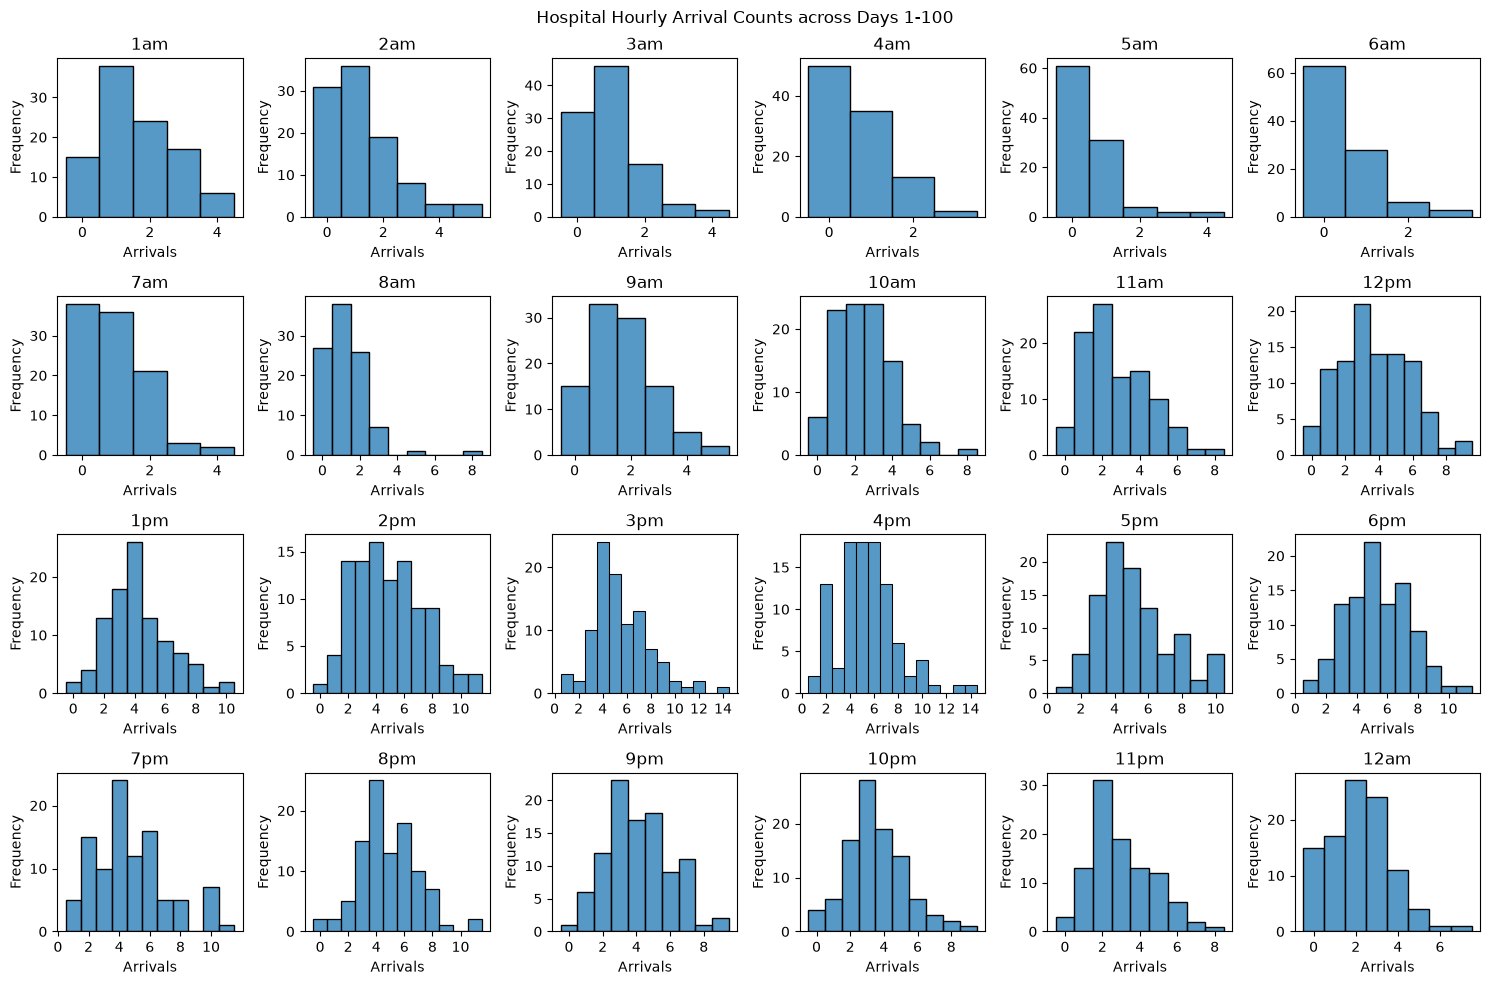

In [46]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
fig.suptitle("Hospital Hourly Arrival Counts across Days 1-100")

axes = axes.flat
for i, col_name in enumerate(df_arrivals.columns):
    ax = axes[i]
    x = df_arrivals[col_name]
    sns.histplot(data=x, discrete=True, ax=ax)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Arrivals")
    ax.set_title(col_name)
    ax.set_xticks(np.arange(0, x.max() + 1, 2))

plt.tight_layout()
plt.show()

In [ ]:
# TODO Calculate Poisson MLEs (sample mean) for each hour

In [ ]:
# TODO Display scaled poisson distribution over visualization to quickly confirm if poisson is a good fit for modeling.

In [ ]:
# TODO Run chi-squared test of observed arrival counts versus proposed Poisson distribution

### Visualizing and modeling service times

In [58]:
# Read treatment (service) time data. Use the ID column (idx 0) as the index.
df_treatment_raw = pd.read_csv("./data/Data_TreatmentTimes.csv", index_col=0)
df_treatment_raw = df_treatment_raw.rename(columns={"Treatment Time (Days)": "TreatmentTime"})
display(df_treatment_raw.head(5))
display(df_treatment_raw.shape)
print(df_treatment_raw["Specialty"].unique())

,TreatmentTime,Specialty
ID,,
0,4.640229,Ortho
1,0.770322,Renal
2,1.911212,Card
3,4.199311,Respi
4,2.527663,Gastro_Endo


(18565, 2)

<StringArray>
['Ortho', 'Renal', 'Card', 'Respi', 'Gastro_Endo']
Length: 5, dtype: str


In [59]:
# Group treatment time data by specialty.
# We assume that the treatment time distribution for a given specialty is the same across all wards under that specialty.
# (We are not given information about service times in each ward.)
df_treatment_by_specialty = df_treatment_raw.groupby(["Specialty"])
display(df_treatment_by_specialty.describe())

TreatmentTime                                              \
                    count      mean       std           min       25%   
Specialty                                                               
Card               4321.0  2.884995  3.515021  5.928158e-02  0.926157   
Gastro_Endo        3254.0  3.375186  3.639022  6.806160e-04  0.815995   
Ortho              3425.0  5.490906  5.491733  3.238330e-04  1.549496   
Renal              3244.0  4.823262  6.828324  2.105476e-07  0.517170   
Respi              4321.0  3.296486  5.696918  4.035753e-02  0.782429   

                                             
                  50%       75%         max  
Specialty                                    
Card         1.774205  3.454252   42.392131  
Gastro_Endo  2.188181  4.703748   28.626801  
Ortho        3.861794  7.595541   52.501056  
Renal        2.228971  6.244268   59.849193  
Respi        1.747665  3.666749  143.763709

In [62]:
# Peek the grouping
for i, (group_name, df_group) in enumerate(df_treatment_by_specialty):
    display(group_name[0])
    display(df_group.head(5))

'Card'

,TreatmentTime,Specialty
ID,,
2,1.911212,Card
5,2.076513,Card
6,1.862886,Card
14,1.343026,Card
17,5.331829,Card


'Gastro_Endo'

,TreatmentTime,Specialty
ID,,
4,2.527663,Gastro_Endo
18,2.758086,Gastro_Endo
27,10.760506,Gastro_Endo
44,0.495989,Gastro_Endo
47,10.935222,Gastro_Endo


'Ortho'

,TreatmentTime,Specialty
ID,,
0,4.640229,Ortho
15,0.653278,Ortho
20,1.716359,Ortho
24,0.549169,Ortho
25,9.000257,Ortho


'Renal'

,TreatmentTime,Specialty
ID,,
1,0.770322,Renal
7,0.001040,Renal
10,11.152471,Renal
11,3.017819,Renal
12,2.317516,Renal


'Respi'

,TreatmentTime,Specialty
ID,,
3,4.199311,Respi
8,0.213762,Respi
9,0.271861,Respi
13,1.609639,Respi
16,9.681560,Respi


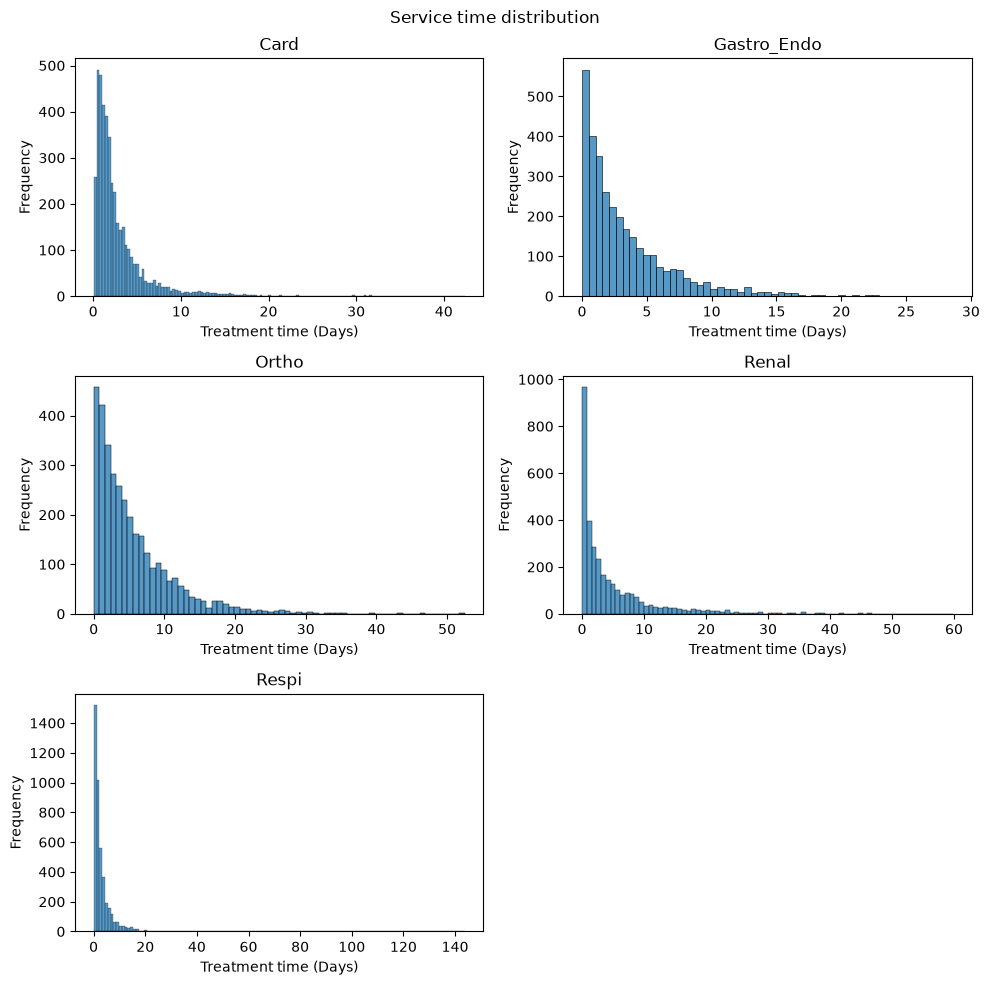

In [ ]:
# Visualize treatment time data by speciality in histograms. (Preliminary.)
fig, axes = plt.subplots(3, 2, figsize=(10, 10))
fig.suptitle("Service time distribution")

axes = axes.flat
for i, (group_name, df_group) in enumerate(df_treatment_by_specialty):
    ax = axes[i]
    sns.histplot(data=df_group["TreatmentTime"], ax=ax)
    ax.set_ylabel("Frequency")
    ax.set_xlabel("Treatment time (Days)")
    ax.set_title(group_name[0])

for ax in axes[i+1:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# TODO On visual inspection, consider what distribution(s) may be the best fit for the five unspecified specialities.